In [1]:
# autoreload
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

from jax import random
import jax.numpy as jnp
import numpy as np

ERROR:2025-11-04 18:17:01,271:jax._src.xla_bridge:473: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/home/dlopez/miniconda3/envs/skewerjax/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 471, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/dlopez/miniconda3/envs/skewerjax/lib/python3.11/site-packages/jax_plugins/xla_cuda13/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/home/dlopez/miniconda3/envs/skewerjax/lib/python3.11/site-packages/jax_plugins/xla_cuda13/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE


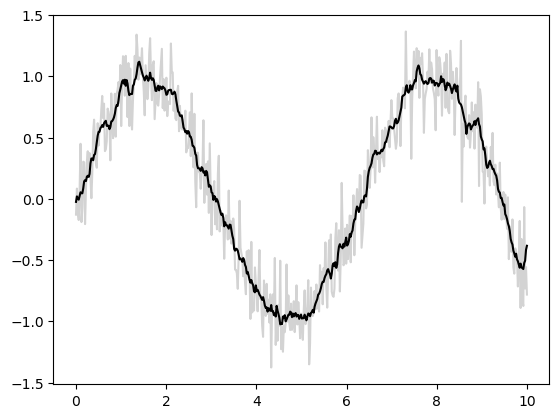

In [2]:
key = random.key(1701)

x = jnp.linspace(0, 10, 500)
y = jnp.sin(x) + 0.2 * random.normal(key, shape=(500,))

window = jnp.ones(10) / 10
y_smooth = jnp.convolve(y, window, mode='same')

plt.plot(x, y, 'lightgray')
plt.plot(x, y_smooth, 'black');

In [3]:
from skewerjax.constants.lines import get_line

lya = get_line("LyA")
print(f"Lyman-alpha λ₀ = {lya.lambda0_A} Å, f = {lya.f_osc}")

lyb = get_line("LyB")
print(f"Lyman-beta frequency = {lyb.nu0_hz:.3e} Hz")


Lyman-alpha λ₀ = 1215.67 Å, f = 0.416
Lyman-beta frequency = 2.923e+15 Hz


In [4]:
%autoreload

In [8]:
import jax.numpy as jnp
from jax import vmap
from skewerjax.constants.physical import phys
from skewerjax.optical_depth.line_profile import thermal_profile, natural_profile, voigt_profile

# Example: H I Lyα at rest
lambda0_A = 1215.67
nu0 = phys.c / (lambda0_A * phys.ANGSTROM)  # Hz
Gamma = 6.265e8  # s^-1
T = 1e4          # K
m_amu = 1.00784

# Frequency grid around the line
nu = jnp.linspace(nu0 - 2e11, nu0 + 2e11, 4096)

phi_L = natural_profile(nu, nu0, Gamma)
phi_G = thermal_profile(nu, nu0, T_K=T, mass_amu=m_amu)
# phi_V = voigt_profile(nu, nu0, Gamma, T_K=T, mass_amu=m_amu)

# Vectorization over many (nu0, T) pairs works out of the box with vmap
Ts = jnp.array([5e3, 1e4, 2e4])
phiV_manyT = vmap(lambda TT: thermal_profile(nu, nu0, T_K=TT, mass_amu=m_amu))(Ts)
